# 11C — Braking, turning and re-acceleration mechanics

**Hypothesis (S11C).** Transition mechanics — braking, turning, re-accelerating — carry football-specific athletic information that straight-line speed does not: they are repeatable across attempts, not explained by the official times, and related to geometry-matched NFL transitions.

**Segmentation (C1).** Physically defined thresholds (the 09A values: a_tan ≤ −1 / ≥ +1 yd/s²) are primary; a changepoint segmentation and a 3-state HMM are compared on the same attempts (frame agreement). No deep sequence model.

**Metrics (C2).** Braking duration and distance · mean and robust peak deceleration · turn-entry and turn-exit speed · Transition Cost Index (v_entry − v_exit)/v_entry · Brake-to-Burst latency · Speed Recovery Time (80 % of entry speed) · peak lateral acceleration · left/right asymmetry (magnitude, comparable entry speeds only). Turn angles are measured from velocity vectors — never assumed from the drill diagram.

**Prerequisites.** 11.0 (feature foundation, NFL targets incl. braking → re-acceleration pairs).

In [1]:
RUN_MODE = 'full'
SEED = 20261011
FORCE_REBUILD = False
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
RUN_PERMUTATION = True

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement.artifacts import DiscoveryStore
from nflbdb.research.advanced_movement.m11 import assemble as asm
from nflbdb.research.advanced_movement.m11 import combine_drills as cd
from nflbdb.research.advanced_movement.m11 import config as m11c
from nflbdb.research.advanced_movement.m11 import evaluation as ev
from nflbdb.research.advanced_movement.m11 import figures as fg
from nflbdb.research.advanced_movement.m11 import reporting as rp
from nflbdb.research.advanced_movement.m11 import segmentation as sg
from nflbdb.research.advanced_movement.m11 import sources as src
from nflbdb.research.advanced_movement.m11 import speed_state as ss
from nflbdb.research.advanced_movement.m11 import tournament as tn
from nflbdb.research.advanced_movement.m11 import transitions as tr
from nflbdb.research.advanced_movement.m11 import validation as v11

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = DiscoveryStore(cfg, controls)
amc.seed_everything(controls.seed)
C = m11c.M11Config().for_mode(controls)
S = src.M11Sources(cfg, store, C)
PROV = m11c.provenance('11C', controls, C)
W = store.write_frame
officials = asm.foundation(store, 'm11_officials')
attempts = asm.foundation(store, 'm11_attempt_features')
athf = asm.foundation(store, 'm11_athlete_features')
trans = asm.foundation(store, 'm11_combine_transitions')
agree = asm.foundation(store, 'm11_segmenter_agreement')
rep = asm.foundation(store, 'm11_repeatability')
FAMS = cd.TRANSITION_FAMILIES
label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · {trans.height:,} Combine transitions in the foundation'))
checks = v11.run_all(v11.CHECKS_TRANSITIONS)
display(checks)
v11.assert_all_passed(checks)

**Run mode: `full`** (FULL) · 1,633 Combine transitions in the foundation

check,status,detail
str,str,str
"""episode_segmentation""","""PASS""","""threshold segmenter finds the …"
"""coordinate_geometry_turn_direc…","""PASS""","""signed turn angles (+ = ccw), …"


## 1 · Data availability and segmentation comparison

Transitions per drill family and position (athletes are the sample size). Segmenter agreement = share of frames labelled with the same state (decelerate · steady · accelerate) by the threshold rule and by the changepoint / HMM alternatives.

family,position_group,n_athletes,n_transitions,share_censored
str,str,u32,u32,f64
"""backpedal_transition""","""DB""",113,322,0.149068
"""backpedal_transition""","""DL""",61,255,0.184314
"""short_shuttle""","""DB""",28,69,0.043478
"""short_shuttle""","""DL""",38,88,0.045455
"""short_shuttle""","""OL""",53,132,0.030303
…,…,…,…,…
"""three_cone""","""DB""",24,71,0.0
"""three_cone""","""DL""",76,214,0.014019
"""three_cone""","""OL""",87,209,0.019139


family,n_attempts,median_agree_changepoint,median_agree_hmm,p10_agree_changepoint,p10_agree_hmm
str,u32,f64,f64,f64,f64
"""backpedal_transition""",732,0.91239,0.827042,0.829925,0.571619
"""short_shuttle""",223,0.909091,0.86,0.857714,0.704435
"""three_cone""",626,0.900617,0.831921,0.834848,0.581667


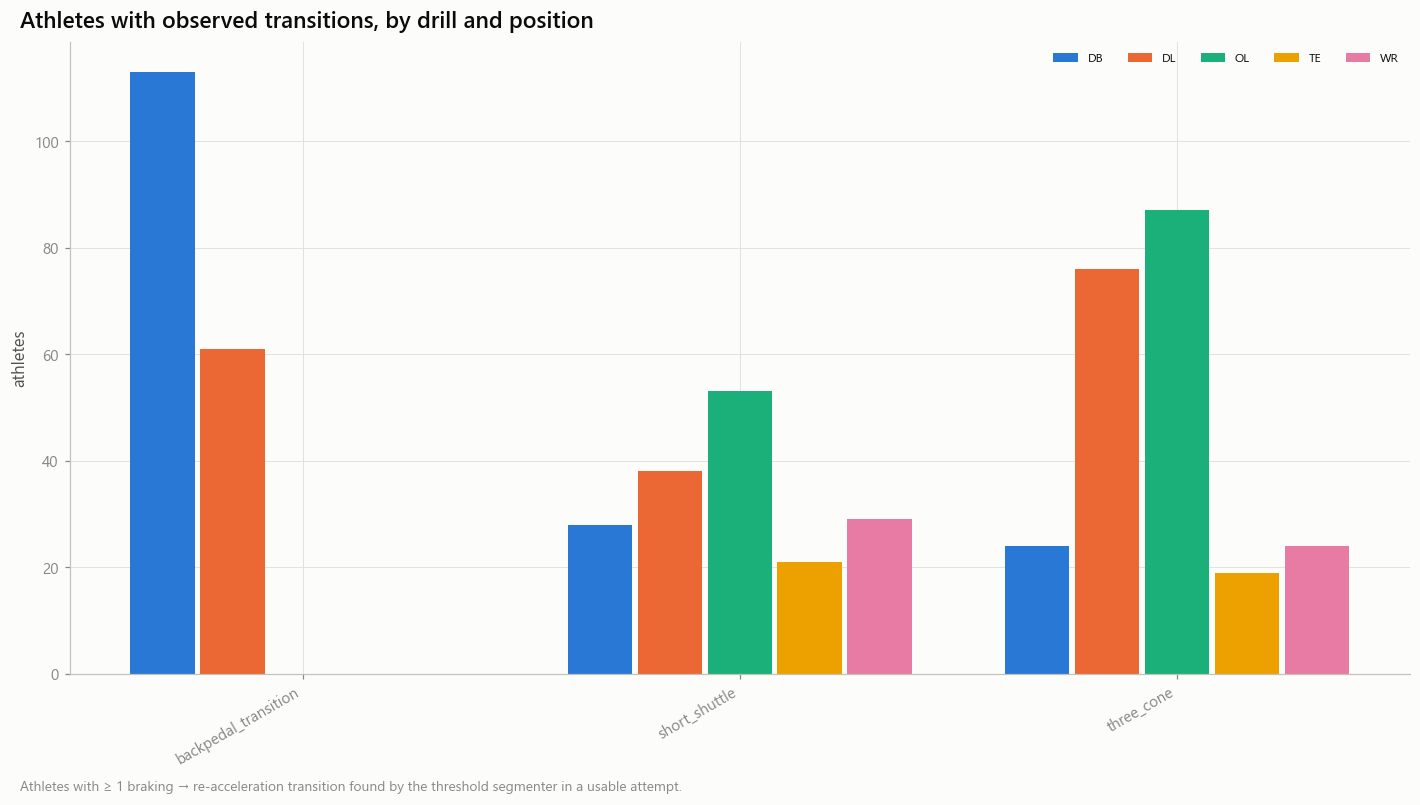

In [3]:
if trans.is_empty():
    display(Markdown('**NOT_FEASIBLE:** no transition-drill attempt produced a transition in this run mode (no shuttle / three-cone / transition drill tracked, or all rejected). The rest of the notebook reports empty tables.'))
tp = trans.join(officials.select('nfl_id', 'position_group'), on='nfl_id', how='left') if trans.height else trans
avail = tp.group_by('family', 'position_group').agg(pl.col('nfl_id').n_unique().alias('n_athletes'), pl.len().alias('n_transitions'), pl.col('censored').mean().alias('share_censored')) if tp.height else pl.DataFrame()
segsum = tr.segmenter_summary(agree)
W(avail, 'm11_transition_availability')
W(segsum, 'm11_segmenter_summary')
display(avail.sort('family', 'position_group') if avail.height else avail)
display(segsum)
if avail.height:
    store.show(fg.fig_grouped_bars(avail, 'family', 'position_group', 'n_athletes', 'Athletes with observed transitions, by drill and position',
                                   'Athletes with ≥ 1 braking → re-acceleration transition found by the threshold segmenter in a usable attempt.', 'athletes'),
               'AM11_C_01_transition_availability', {'availability': avail}, publication=True, source='m11_combine_transitions')

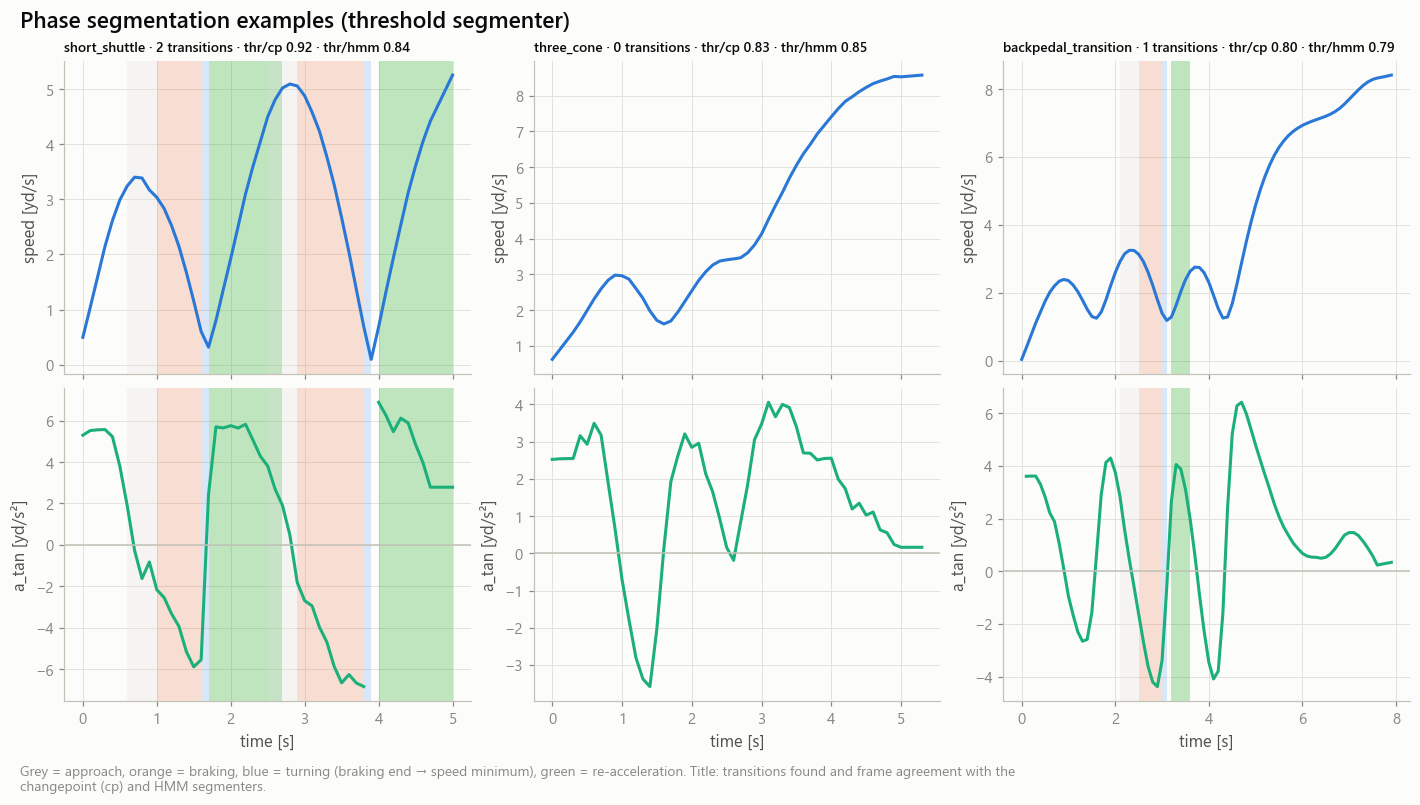

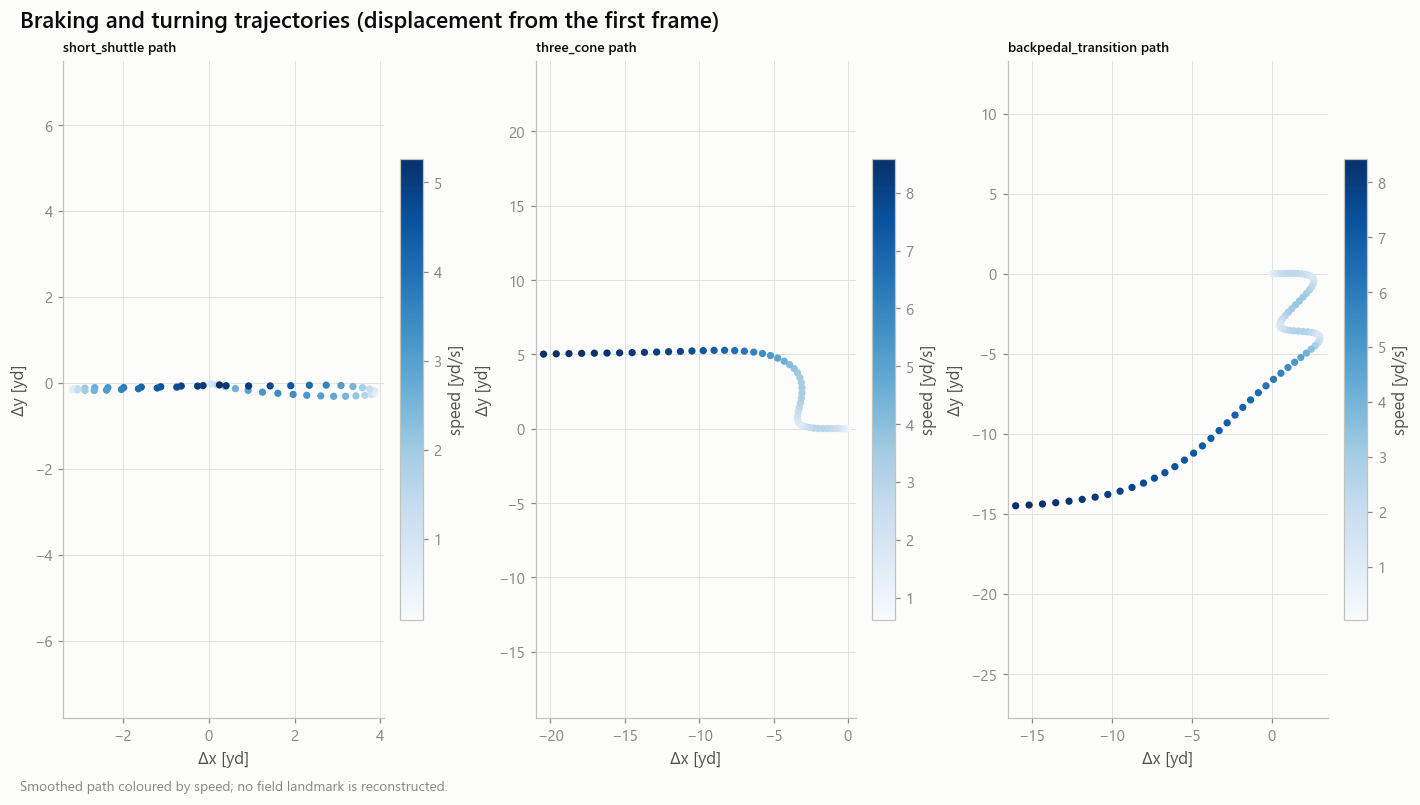

In [4]:
# phase-segmentation examples: the attempt with the median number of frames in each transition family (rule-chosen)
idx = asm.foundation(store, 'm11_attempt_index')
frames = S.combine_frames(list(FAMS)) if trans.height else None
traces, paths = [], []
for fam in FAMS:
    cand = idx.filter((pl.col('family') == fam) & (pl.col('n_frames') >= 20)).sort('n_frames', 'seq_id') if frames is not None else idx.clear()
    if cand.height == 0:
        continue
    sid = cand['seq_id'][cand.height // 2]
    f = cd.longest_segment(frames.filter(pl.col('seq_id') == sid))
    t = f['t_s'].to_numpy() - f['t_s'][0]
    v, a = f['speed'].to_numpy(), f['a_tan'].to_numpy()
    vx = f['vx'].to_numpy() if 'vx' in f.columns else None
    vy = f['vy'].to_numpy() if 'vy' in f.columns else None
    ts = sg.transitions(t, v, a, vx, vy)
    ph_ = []
    for d in ts:
        ph_ += [(t[d['i_approach']], t[d['i_brake']], 'approach'), (t[d['i_brake']], t[d['i_brake_end'] - 1], 'braking'), (t[d['i_brake_end'] - 1], t[d['i_min']], 'turning')]
        if d['i_accel'] >= 0:
            ph_.append((t[d['i_accel']], t[d['i_accel_end'] - 1], 'reacceleration'))
    agr = f"thr/cp {sg.agreement(sg.threshold_labels(a), sg.changepoint_labels(a)):.2f} · thr/hmm {sg.agreement(sg.threshold_labels(a), sg.hmm_labels(a)):.2f}"
    traces.append({'t': t, 'speed': v, 'a_tan': a, 'phases': ph_, 'title': f'{fam} · {len(ts)} transitions · {agr}'})
    if 'x_s' in f.columns:
        paths.append({'x': f['x_s'].to_numpy(), 'y': f['y_s'].to_numpy(), 'speed': v, 'title': f'{fam} path'})
if traces:
    store.show(fg.fig_traces(traces, 'Phase segmentation examples (threshold segmenter)',
                             'Grey = approach, orange = braking, blue = turning (braking end → speed minimum), green = re-acceleration. Title: transitions found and frame agreement with the changepoint (cp) and HMM segmenters.'),
               'AM11_C_02_segmentation_examples', {}, publication=True, source='combine frames')
if paths:
    store.show(fg.fig_paths(paths, 'Braking and turning trajectories (displacement from the first frame)', 'Smoothed path coloured by speed; no field landmark is reconstructed.'),
               'AM11_C_03_trajectories', {}, publication=False, source='combine frames')

## 2 · Metric distributions, Transition Cost versus turn angle, repeatability and redundancy

Repeatability = ICC(1) across attempts (athlete bootstrap CI, from 11.0). Variance decomposition of transition-level values in a DECLARED order: drill → |angle| bin → direction → athlete; the remainder is sensor noise plus within-athlete variation. Redundancy = within-position R² from the official forty, 10-yd split and the drill's own official time.

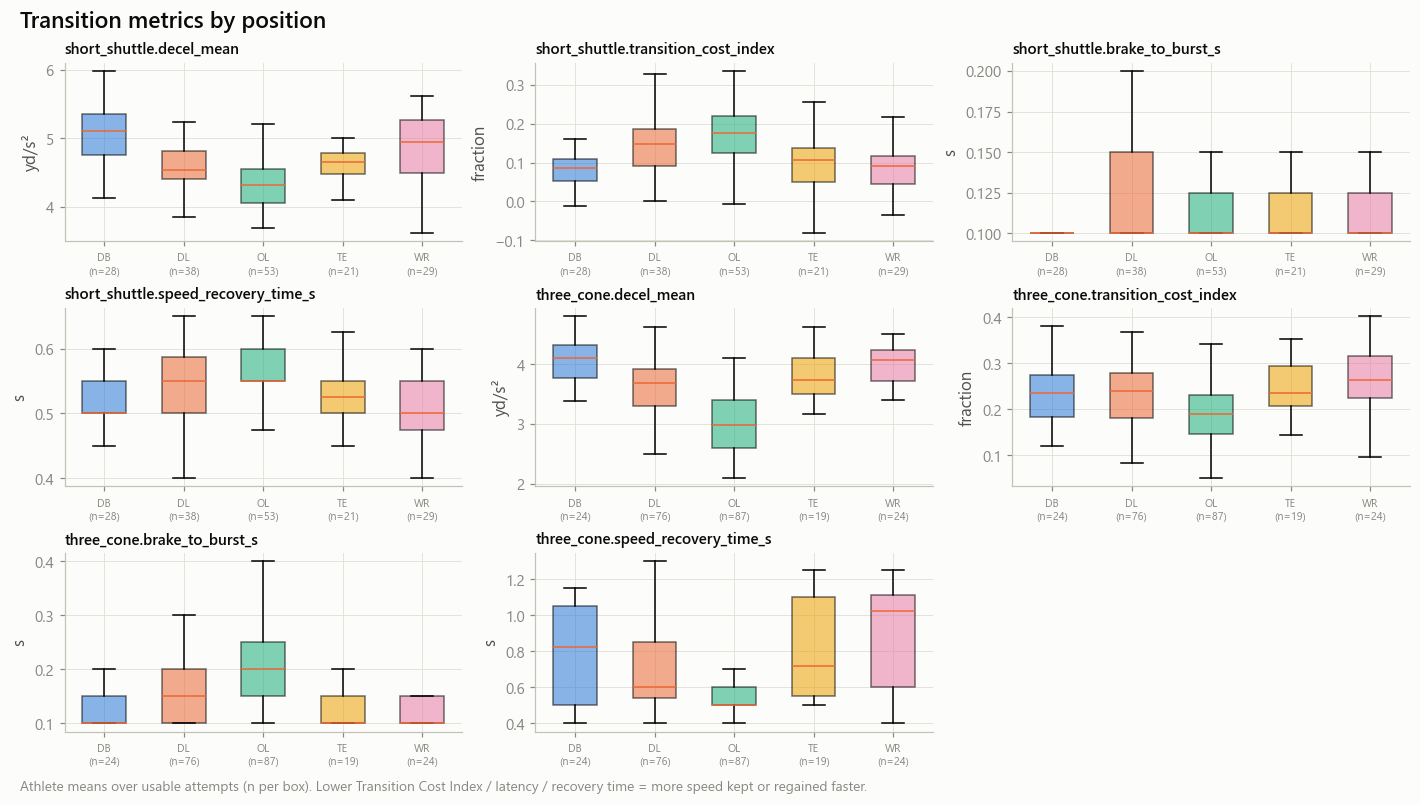

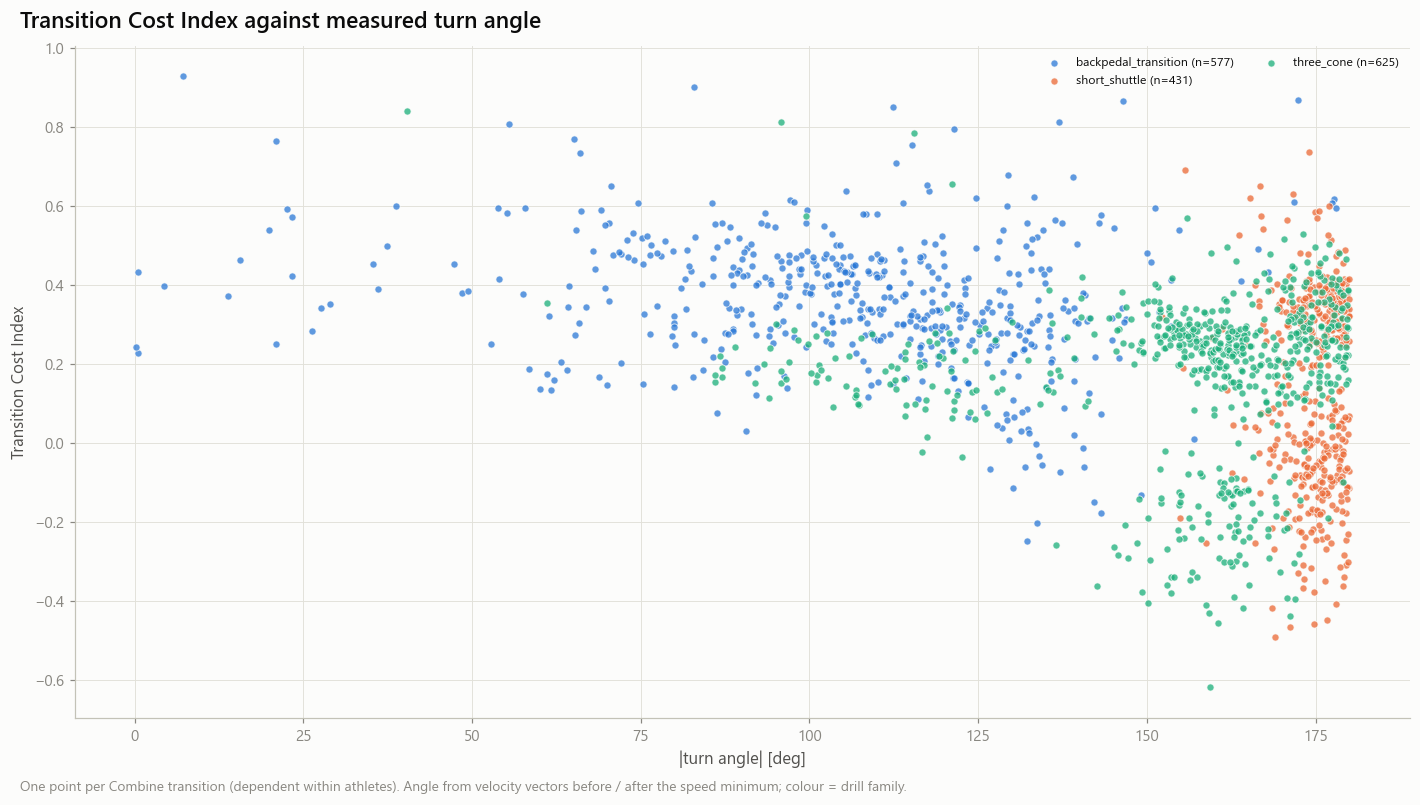

feature,n_athletes,n_repeat,icc,icc_lo,icc_hi
str,i64,i64,f64,f64,f64
"""short_shuttle.curved_speed""",0,0,NaN,NaN,NaN
"""three_cone.brake_time_5_2_s""",11,0,NaN,NaN,NaN
"""short_shuttle.approach_speed""",169,40,0.653776,0.520599,0.744182
"""short_shuttle.brake_time_5_2_s""",155,32,0.576629,0.383106,0.763846
"""short_shuttle.tci_cw""",132,27,0.545491,0.335773,0.722142
"""short_shuttle.lat_accel_peak""",169,40,0.542696,0.266707,0.753771
"""three_cone.tci_cw""",112,12,0.509061,NaN,NaN
"""short_shuttle.tci_ccw""",136,28,0.437949,0.227756,0.606671
"""short_shuttle.state_changes_pe…",170,42,0.364251,0.0,0.703796


metric,n_transitions,n_athletes,status,r2_drill,r2_geometry,r2_direction,r2_athlete,residual_share
str,i64,i64,str,f64,f64,f64,f64,f64
"""decel_mean""",1633,367,"""computed""",0.577728,0.046682,0.00227,0.087396,0.285923
"""transition_cost_index""",1583,366,"""computed""",0.238587,0.013028,0.00004,0.084915,0.66343
"""brake_to_burst_s""",1575,366,"""computed""",0.3143,0.214898,0.000608,0.110835,0.359359
"""speed_recovery_time_s""",1532,366,"""computed""",0.303212,0.076961,0.002068,0.158014,0.459745
"""exit_accel""",1555,366,"""computed""",0.651631,0.021611,0.000106,0.077908,0.248743
"""braking_distance_yd""",1633,367,"""computed""",0.784263,0.011245,0.002261,0.035602,0.166629


metric,officials,n_athletes,r2_official
str,str,i64,f64
"""backpedal_transition.v_min""","""forty, ten""",144,0.000017
"""backpedal_transition.approach_…","""forty, ten""",144,0.000837
"""backpedal_transition.brake_to_…","""forty, ten""",143,0.00126
"""backpedal_transition.state_cha…","""forty, ten""",152,0.001365
"""backpedal_transition.decel_pea…","""forty, ten""",144,0.001604
"""backpedal_transition.decel_pea…","""forty, ten""",144,0.00166
"""backpedal_transition.entry_spe…","""forty, ten""",144,0.001788
"""backpedal_transition.exit_spee…","""forty, ten""",143,0.002049
"""backpedal_transition.turn_angl…","""forty, ten""",143,0.002299


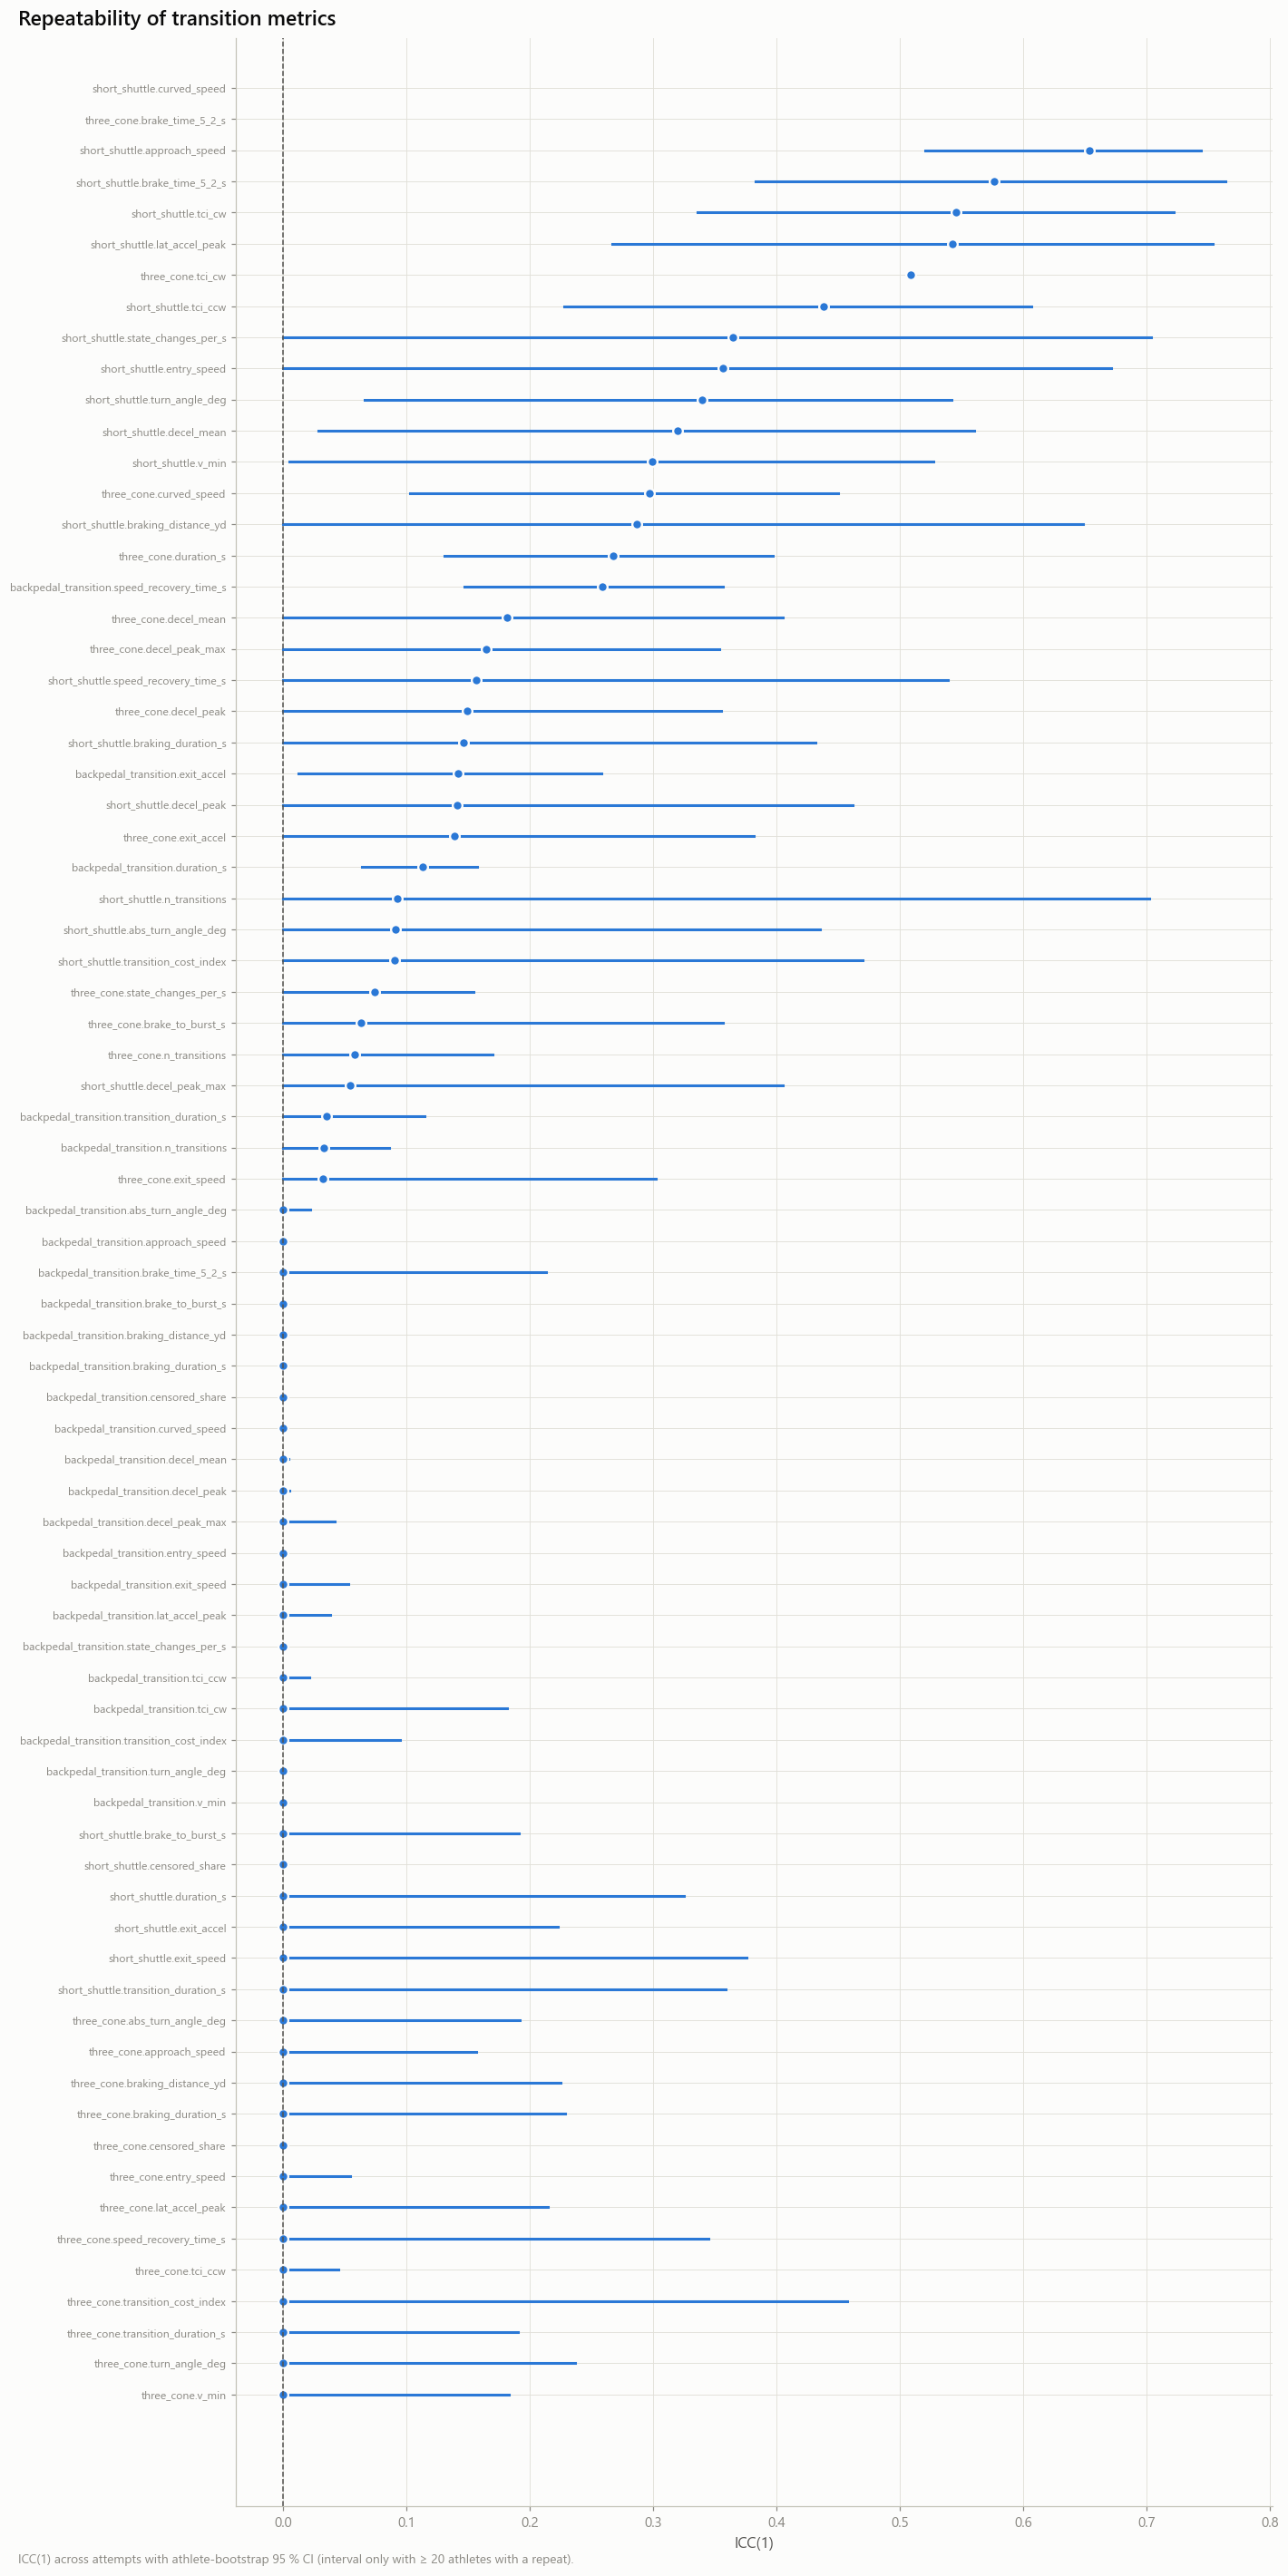

In [5]:
KEY = [f'{fam}.{m}' for fam in ('short_shuttle', 'three_cone') for m in ('decel_mean', 'transition_cost_index', 'brake_to_burst_s', 'speed_recovery_time_s')]
long = athf.filter(pl.col('feature').is_in(KEY)).join(officials.select('nfl_id', 'position_group'), on='nfl_id', how='left')
units = {k: sg.METRIC_UNITS.get(k.split('.')[-1], '') for k in KEY}
store.show(fg.fig_distributions(long, 'feature', 'value', 'position_group', [k for k in KEY if k in set(long['feature'].to_list())], 'Transition metrics by position',
                                'Athlete means over usable attempts (n per box). Lower Transition Cost Index / latency / recovery time = more speed kept or regained faster.', units),
           'AM11_C_04_metric_distributions', {'metrics_long': long}, publication=True, source='m11_athlete_features')
if trans.height:
    store.show(fg.fig_scatter(trans.filter(pl.col('abs_turn_angle_deg').is_not_null()), 'abs_turn_angle_deg', 'transition_cost_index', 'Transition Cost Index against measured turn angle',
                              'One point per Combine transition (dependent within athletes). Angle from velocity vectors before / after the speed minimum; colour = drill family.',
                              '|turn angle| [deg]', 'Transition Cost Index', color='family'), 'AM11_C_05_tci_vs_angle', {}, publication=True, source='m11_combine_transitions')
rep_t = rep.filter(pl.col('feature').str.split('.').list.first().is_in(list(FAMS)))
W(rep_t, 'm11_transition_repeatability')
vd = tr.variance_decomposition(trans, ['decel_mean', 'transition_cost_index', 'brake_to_burst_s', 'speed_recovery_time_s', 'exit_accel', 'braking_distance_yd'], C.angle_bins) if trans.height else pl.DataFrame()
W(vd, 'm11_transition_variance')
metrics = sorted(set(athf.filter(pl.col('family').is_in(list(FAMS)))['feature'].to_list()))
wide_t = cd.wide(athf.filter(pl.col('feature').is_in(metrics)))
red = tr.redundancy_rows(wide_t, officials, metrics)
W(red, 'm11_transition_redundancy')
with pl.Config(tbl_rows=-1, tbl_width_chars=220):
    display(rep_t.sort('icc', descending=True, nulls_last=True))
    display(vd)
    display(red.sort('r2_official', nulls_last=True) if red.height else red)
if rep_t.height:
    store.show(fg.fig_forest(rep_t.sort('icc', descending=True, nulls_last=True), 'feature', 'icc', 'icc_lo', 'icc_hi', 'Repeatability of transition metrics',
                             'ICC(1) across attempts with athlete-bootstrap 95 % CI (interval only with ≥ 20 athletes with a repeat).', 'ICC(1)'),
               'AM11_C_06_repeatability', {'repeatability': rep_t}, publication=True, source='m11_repeatability')

## 3 · NFL matching by geometry

Entry-speed × |turn angle| cells counted in both domains: NFL brake → re-acceleration pairs with an observed turn, and redirection episodes (turns at ≥ 3 yd/s). Only cells with enough athletes in BOTH domains are compared. Combine reversals pass through a near-stop; most NFL turns do not — the table shows how much geometry the domains actually share.

entry_speed_bin,angle_bin,n_combine,athletes_combine,n_nfl,athletes_nfl,n_nfl_brake_reaccel,shared_cell
str,str,u32,u32,u32,u32,u32,bool
"""[-inf, 2)""","""[135, 181)""",25,25,0,0,0,false
"""[2, 4)""",null,1,1,0,0,0,false
"""[2, 4)""","""[135, 181)""",602,218,119,72,0,true
"""[2, 4)""","""[181, inf)""",0,0,19,16,0,false
"""[2, 4)""","""[45, 90)""",7,7,5903,337,0,false
…,…,…,…,…,…,…,…
"""[6, 12)""",null,48,45,0,0,0,false
"""[6, 12)""","""[-inf, 45)""",16,16,0,0,0,false
"""[6, 12)""","""[135, 181)""",19,18,13,13,8,false


Total geometry cells: 17
Valid geometry cells: 14
Excluded null-bin rows: 3


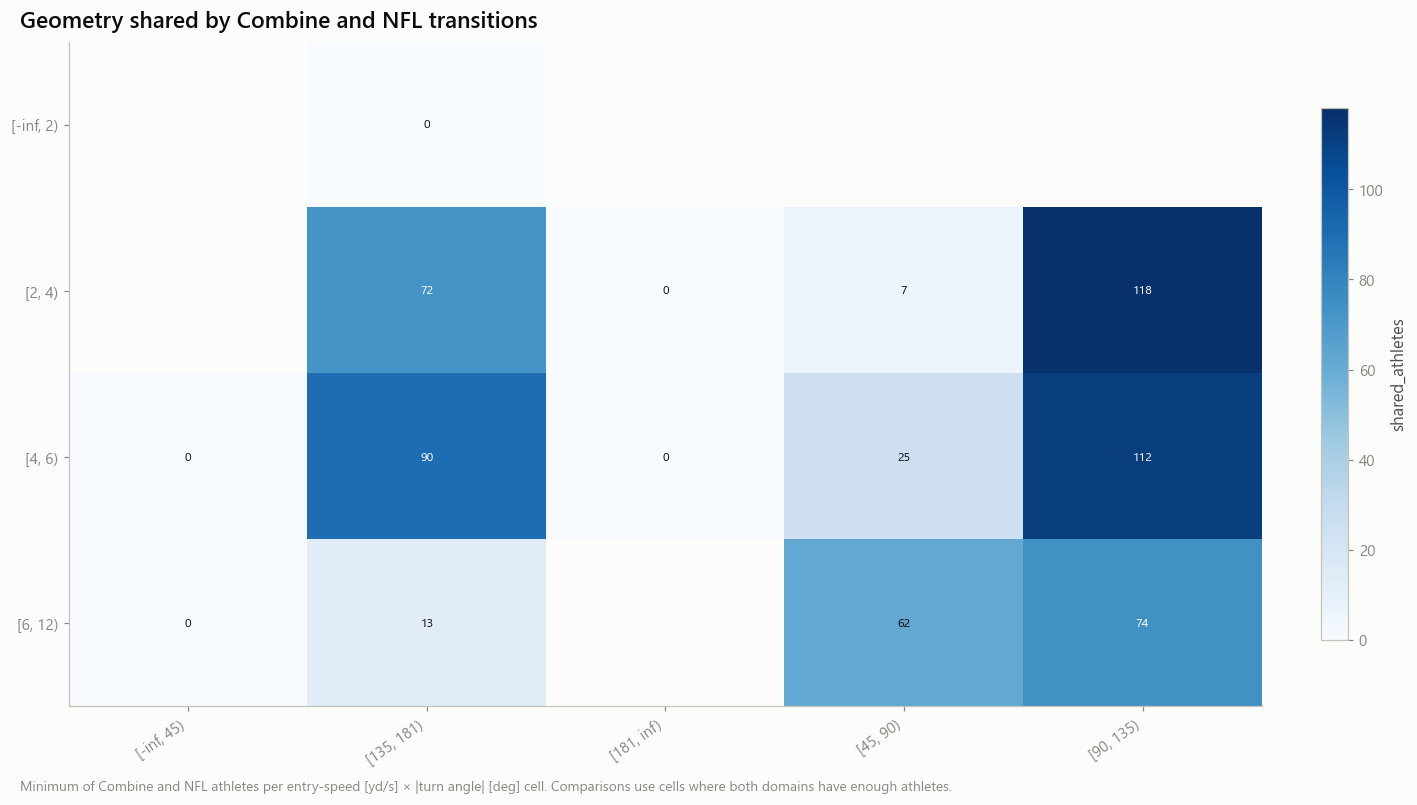

**Asymmetry:** 57 athletes with comparable turns in both directions (magnitude only; frame handedness unverified).

In [7]:

# ================================================================
# M11 — Geometry overlap and asymmetry
# ================================================================

episodes = S.episodes()
pairs = asm.foundation(store, "m11_brake_reaccel_pairs")

cells = (
    tr.geometry_cells(trans, pairs, episodes, C)
    if trans.height
    else pl.DataFrame()
)

W(cells, "m11_geometry_cells")
display(cells)

# ------------------------------------------------------------
# Geometry overlap heatmap
# ------------------------------------------------------------

if cells.height:

    required_cols = [
        "entry_speed_bin",
        "angle_bin",
        "athletes_combine",
        "athletes_nfl",
    ]

    missing_cols = [
        col for col in required_cols
        if col not in cells.columns
    ]

    if missing_cols:
        print(
            f"Geometry heatmap skipped: missing columns {missing_cols}"
        )

    else:
        valid_cells = (
            cells
            .filter(
                pl.col("entry_speed_bin").is_not_null()
                & pl.col("angle_bin").is_not_null()
            )
            .with_columns(
                pl.min_horizontal(
                    "athletes_combine",
                    "athletes_nfl",
                ).alias("shared_athletes")
            )
        )

        dropped = cells.height - valid_cells.height

        print(f"Total geometry cells: {cells.height:,}")
        print(f"Valid geometry cells: {valid_cells.height:,}")
        print(f"Excluded null-bin rows: {dropped:,}")

        if valid_cells.height:
            fig = fg.fig_heatmap(
                valid_cells,
                "entry_speed_bin",
                "angle_bin",
                "shared_athletes",
                "Geometry shared by Combine and NFL transitions",
                (
                    "Minimum of Combine and NFL athletes per "
                    "entry-speed [yd/s] × |turn angle| [deg] cell. "
                    "Comparisons use cells where both domains "
                    "have enough athletes."
                ),
            )

            store.show(
                fig,
                "AM11_C_07_geometry_overlap",
                {"cells": valid_cells},
                publication=True,
                source="m11_geometry_cells",
            )

        else:
            print(
                "Geometry heatmap skipped: "
                "no valid non-null geometry bins."
            )

# ------------------------------------------------------------
# Combine geometry metrics
# ------------------------------------------------------------

geo = (
    tr.combine_geometry_metrics(trans)
    if trans.height
    else pl.DataFrame()
)

asy = (
    tr.asymmetry(trans)
    if trans.height
    else pl.DataFrame()
)

W(geo, "m11_combine_geometry_metrics")
W(asy, "m11_asymmetry")

# ------------------------------------------------------------
# Asymmetry reporting
# ------------------------------------------------------------

if asy.height and "comparable" in asy.columns:

    comparable_count = (
        asy.select(
            pl.col("comparable")
            .fill_null(False)
            .cast(pl.Int64)
            .sum()
        )
        .item()
    )

    display(
        Markdown(
            f"**Asymmetry:** {comparable_count:,} athletes "
            "with comparable turns in both directions "
            "(magnitude only; frame handedness unverified)."
        )
    )


## 4 · NFL relevance — association and held-out ladder

Declared pairs `transitions.TRANSFER_PAIRS` (incl. the geometry-matched Transition Cost Index of ≥ 90° turns and two NEGATIVE CONTROLS). Expected sign: positive except Combine TCI vs NFL speed RETENTION (negative). Held-out: M1 (context + official forty, 10-yd split) vs M1 + metric.

combine,nfl,kind,n_athletes,spearman,spearman_lo,spearman_hi,partial_spearman,pearson_disattenuated,mde_r,reading,status
str,str,str,i64,f64,f64,f64,f64,f64,f64,str,str
"""short_shuttle.decel_mean""","""nfl.brake_decel""","""matched""",101,0.607699,0.473584,0.708639,0.213125,1.0,0.27839,"""association (interval excludes 0) — descriptive""","""computed"""
"""short_shuttle.decel_peak""","""nfl.brake_peak05""","""matched""",101,0.62304,0.495392,0.732784,0.135782,NaN,0.27839,"""association (interval excludes 0) — descriptive""","""computed"""
"""short_shuttle.braking_distance_yd""","""nfl.brake_distance_matched""","""matched""",100,0.069547,-0.14939,0.278111,0.044781,NaN,0.279774,"""inconclusive (|r| below ≈ 0.28 is not detectable at this n)""","""computed"""
"""short_shuttle.brake_to_burst_s""","""nfl.brake_to_burst""","""matched""",72,0.136993,-0.074146,0.340003,0.126196,NaN,0.329501,"""inconclusive (|r| below ≈ 0.33 is not detectable at this n)""","""computed"""
"""short_shuttle.exit_accel""","""nfl.reaccel_mean""","""matched""",72,0.606406,0.4094,0.751946,0.280532,NaN,0.329501,"""association (interval excludes 0) — descriptive""","""computed"""
"""short_shuttle.transition_cost_index""","""nfl.pair_tci""","""matched""",72,0.245546,0.014793,0.458762,0.142717,NaN,0.329501,"""association (interval excludes 0) — descriptive""","""computed"""
"""three_cone.transition_cost_index""","""nfl.redirect_retention_90""","""matched""",18,-0.378741,NaN,NaN,-0.440693,NaN,0.650993,"""too few athletes for an interval""","""computed"""
"""three_cone.curved_speed""","""nfl.redirect_retention""","""physics""",78,-0.09837,-0.314736,0.132726,0.093745,NaN,0.316633,"""inconclusive (|r| below ≈ 0.32 is not detectable at this n)""","""computed"""
"""three_cone.exit_accel""","""nfl.reaccel_mean""","""matched""",87,0.142469,-0.091198,0.349514,0.139189,NaN,0.299876,"""inconclusive (|r| below ≈ 0.30 is not detectable at this n)""","""computed"""


combine,kind,target,model,reference,n_athletes,rmse_ref,rmse_model,delta_rmse,delta_lo,delta_hi,delta_pct,spearman_ref,spearman_model,r2_ref,r2_model,p_boot_le0,verdict
str,str,str,str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""short_shuttle.decel_mean""","""matched""","""nfl.brake_decel""","""M2""","""M1""",111,0.194565,0.194519,0.000045,-0.00103,0.001222,0.023303,0.774245,0.77335,0.634468,0.634638,0.465,"""inconclusive"""
"""short_shuttle.decel_peak""","""matched""","""nfl.brake_peak05""","""M2""","""M1""",111,0.266652,0.267342,-0.00069,-0.003299,0.001771,-0.258804,0.790163,0.785126,0.669612,0.6679,0.729,"""inconclusive"""
"""short_shuttle.braking_distance_yd""","""matched""","""nfl.brake_distance_matched""","""M2""","""M1""",110,0.330206,0.325092,0.005114,-0.003336,0.018468,1.548654,0.640376,0.662755,0.592366,0.604894,0.246,"""inconclusive"""
"""short_shuttle.brake_to_burst_s""","""matched""","""nfl.brake_to_burst""","""M2""","""M1""",77,0.021995,0.021798,0.000197,-0.00015,0.000523,0.896647,0.184882,0.216169,0.040664,0.05779,0.121,"""inconclusive"""
"""short_shuttle.exit_accel""","""matched""","""nfl.reaccel_mean""","""M2""","""M1""",77,0.190969,0.191714,-0.000745,-0.003505,0.001969,-0.390032,0.790289,0.783664,0.707389,0.705102,0.69,"""inconclusive"""
"""short_shuttle.transition_cost_index""","""matched""","""nfl.pair_tci""","""M2""","""M1""",77,0.0468,0.046795,0.000006,-0.000397,0.00033,0.01195,0.704848,0.705847,0.535406,0.535517,0.425,"""inconclusive"""
"""three_cone.transition_cost_index""","""matched""","""nfl.redirect_retention_90""","""M2""","""M1""",24,0.070912,0.070051,0.000861,-0.000917,0.002869,1.213889,-0.162609,-0.092174,0.095071,0.116907,0.232,"""inconclusive"""
"""three_cone.curved_speed""","""physics""","""nfl.redirect_retention""","""M2""","""M1""",92,0.066673,0.066479,0.000194,-0.001812,0.002235,0.291235,0.587719,0.564632,0.326128,0.330048,0.407,"""inconclusive"""
"""three_cone.exit_accel""","""matched""","""nfl.reaccel_mean""","""M2""","""M1""",100,0.189744,0.189961,-0.000217,-0.003717,0.003469,-0.114257,0.761752,0.740294,0.695919,0.695224,0.524,"""inconclusive"""


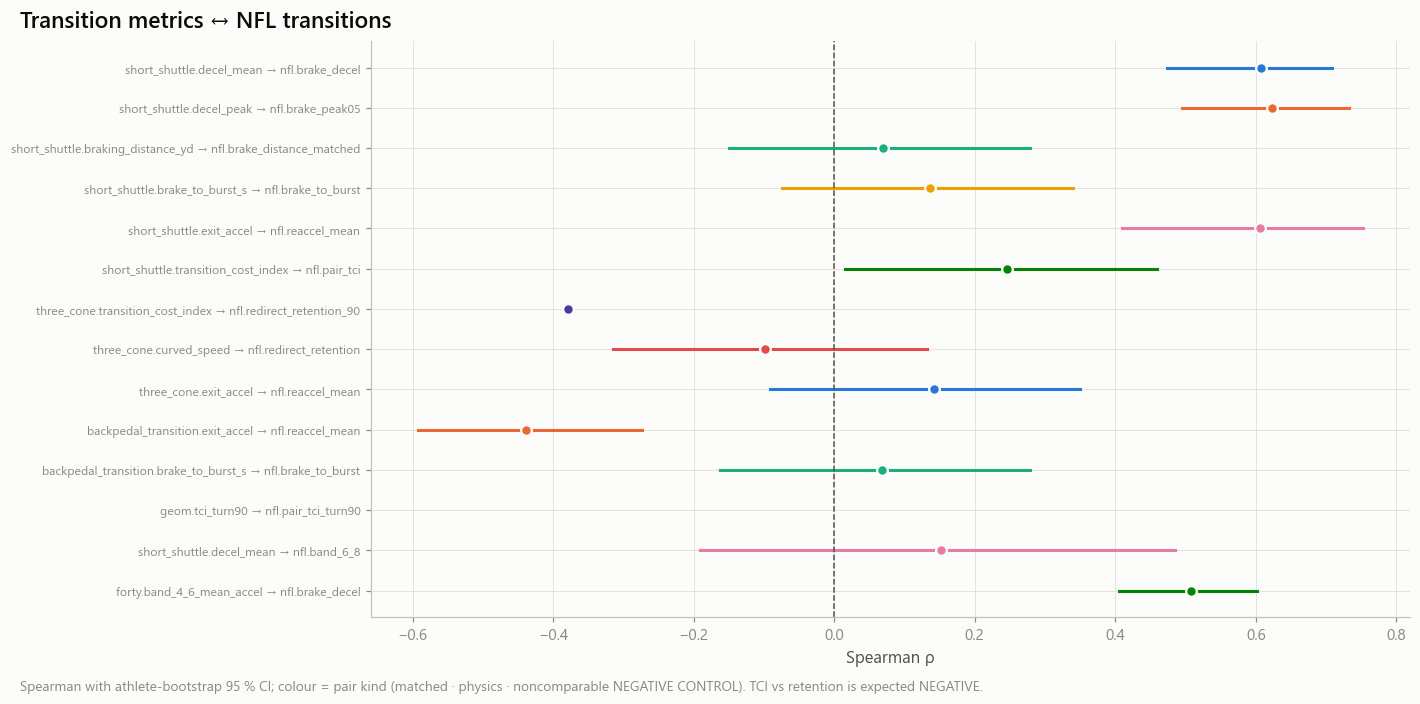

observed,null_mean,null_q95,p_value,n_perm
f64,f64,f64,f64,i64
0.000045,-0.000548,0.000746,0.432836,200


In [8]:
geow = geo.pivot(on='feature', index='nfl_id', values='value') if geo.height else pl.DataFrame({'nfl_id': pl.Series([], dtype=pl.Int64)})
data = asm.linked_table(store, extra=[geow])
RELMAP = asm.reliability_map(store)
assoc, held = ss.direct_transfer(data.drop('fold', 'fold_source'), tr.TRANSFER_PAIRS, RELMAP, data.select('nfl_id', 'fold'), C, C.seed)
W(assoc, 'm11_transition_transfer')
W(held, 'm11_transition_heldout')
with pl.Config(tbl_rows=-1, tbl_width_chars=260, fmt_str_lengths=60):
    display(assoc.select([c for c in ('combine', 'nfl', 'kind', 'n_athletes', 'spearman', 'spearman_lo', 'spearman_hi', 'partial_spearman', 'pearson_disattenuated', 'mde_r', 'reading', 'status') if c in assoc.columns]))
    display(held)
fa = assoc.filter(pl.col('status') == 'computed').with_columns((pl.col('combine') + ' → ' + pl.col('nfl')).alias('pair')) if 'status' in assoc.columns else assoc
store.show(fg.fig_forest(fa, 'pair', 'spearman', 'spearman_lo', 'spearman_hi', 'Transition metrics ↔ NFL transitions',
                         'Spearman with athlete-bootstrap 95 % CI; colour = pair kind (matched · physics · noncomparable NEGATIVE CONTROL). TCI vs retention is expected NEGATIVE.', 'Spearman ρ', color_by='kind'),
           'AM11_C_08_transfer_forest', {'assoc': fa}, publication=True, source='m11_transition_transfer')
control = {}
feat, tgt = 'short_shuttle.decel_mean', 'nfl.brake_decel'
if RUN_PERMUTATION and feat in data.columns and tgt in data.columns:
    sub = data.filter(pl.col(feat).is_not_null() & pl.col(tgt).is_not_null())
    if sub.height >= C.min_athletes_limited:
        base = [*ev.CONTEXT, *ev.OFFICIAL_CORE]
        control = ev.permutation_null(sub, tgt, base, [*base, feat], sub['fold'].to_numpy(), C, C.seed)
        W(pl.DataFrame([{**control, 'feature': feat, 'target': tgt}]), 'm11_transition_controls')
        display(pl.DataFrame([control]))

## 5 · Metric evidence and conclusion

## 11C — conclusion (inconclusive; run mode full; generated 2026-10-14T22:49:26Z)

### Research question
Are braking, turning and re-acceleration metrics repeatable, distinct from the stopwatch, and related to NFL transitions?

### Hypothesis
Transition metrics have ICC ≥ 0.5 across attempts and held-out association with geometry-matched NFL transitions.

### Sample
367 Combine athletes with transitions (1,633 transitions); 387 linked athletes with ≥ 1 supported NFL target.

### Main evidence
- repeatable (ICC lower bound ≥ 0.5): short_shuttle.approach_speed, short_shuttle.curved_speed, three_cone.brake_time_5_2_s, three_cone.tci_cw
- short_shuttle.decel_mean → nfl.brake_decel: ρ 0.608 [0.474, 0.709], n=101 — association (interval excludes 0) — descriptive
- short_shuttle.decel_peak → nfl.brake_peak05: ρ 0.623 [0.495, 0.733], n=101 — association (interval excludes 0) — descriptive
- short_shuttle.braking_distance_yd → nfl.brake_distance_matched: ρ 0.070 [-0.149, 0.278], n=100 — inconclusive (|r| below ≈ 0.28 is not detectable at this n)
- short_shuttle.brake_to_burst_s → nfl.brake_to_burst: ρ 0.137 [-0.074, 0.340], n=72 — inconclusive (|r| below ≈ 0.33 is not detectable at this n)
- short_shuttle.exit_accel → nfl.reaccel_mean: ρ 0.606 [0.409, 0.752], n=72 — association (interval excludes 0) — descriptive
- short_shuttle.transition_cost_index → nfl.pair_tci: ρ 0.246 [0.015, 0.459], n=72 — association (interval excludes 0) — descriptive
- three_cone.transition_cost_index → nfl.redirect_retention_90: ρ -0.379 [—, —], n=18 — too few athletes for an interval
- three_cone.exit_accel → nfl.reaccel_mean: ρ 0.142 [-0.091, 0.350], n=87 — inconclusive (|r| below ≈ 0.30 is not detectable at this n)
- backpedal_transition.exit_accel → nfl.reaccel_mean: ρ -0.438 [-0.592, -0.274], n=92 — association (interval excludes 0) — descriptive
- backpedal_transition.brake_to_burst_s → nfl.brake_to_burst: ρ 0.067 [-0.163, 0.278], n=92 — inconclusive (|r| below ≈ 0.29 is not detectable at this n)
- geom.tci_turn90 → nfl.pair_tci_turn90: ρ — [—, —], n=0 — too few athletes for an interval
- held-out short_shuttle.decel_mean → nfl.brake_decel: Δ RMSE 0.0000 [-0.0010, 0.0012] (inconclusive)
- held-out short_shuttle.decel_peak → nfl.brake_peak05: Δ RMSE -0.0007 [-0.0033, 0.0018] (inconclusive)
- held-out short_shuttle.braking_distance_yd → nfl.brake_distance_matched: Δ RMSE 0.0051 [-0.0033, 0.0185] (inconclusive)
- held-out short_shuttle.brake_to_burst_s → nfl.brake_to_burst: Δ RMSE 0.0002 [-0.0001, 0.0005] (inconclusive)
- held-out short_shuttle.exit_accel → nfl.reaccel_mean: Δ RMSE -0.0007 [-0.0035, 0.0020] (inconclusive)
- held-out short_shuttle.transition_cost_index → nfl.pair_tci: Δ RMSE 0.0000 [-0.0004, 0.0003] (inconclusive)
- held-out three_cone.transition_cost_index → nfl.redirect_retention_90: Δ RMSE 0.0009 [-0.0009, 0.0029] (inconclusive)
- held-out three_cone.curved_speed → nfl.redirect_retention: Δ RMSE 0.0002 [-0.0018, 0.0022] (inconclusive)
- segmenter agreement (median): backpedal_transition cp 0.91 / hmm 0.83, short_shuttle cp 0.91 / hmm 0.86, three_cone cp 0.90 / hmm 0.83

### Alternative explanations
- Drill technique (footwork coaching, plant foot) changes transition metrics without a capacity difference.
- NFL transitions follow routes and coverage; their geometry is chosen, not imposed.
- Non-forty participation is selected (see 11G).

### Practical scouting relevance
Braking and re-acceleration are what the forty cannot see; a repeatable, nonredundant transition metric adds a measurable dimension even if NFL transfer is unproven.

### Limitations
- 10 Hz sampling coarsens braking onset and latency (± 0.1 s).
- Combine reversals pass through a stop, NFL turns mostly do not: few shared geometry cells.
- Burst thresholds differ by domain (declared).

### Next experiment
- Collect tracked deceleration and cutting tests with controlled entry speed (10C proposals).
- Repeat the geometry-matched comparison when more NFL turns with valid headings are available.


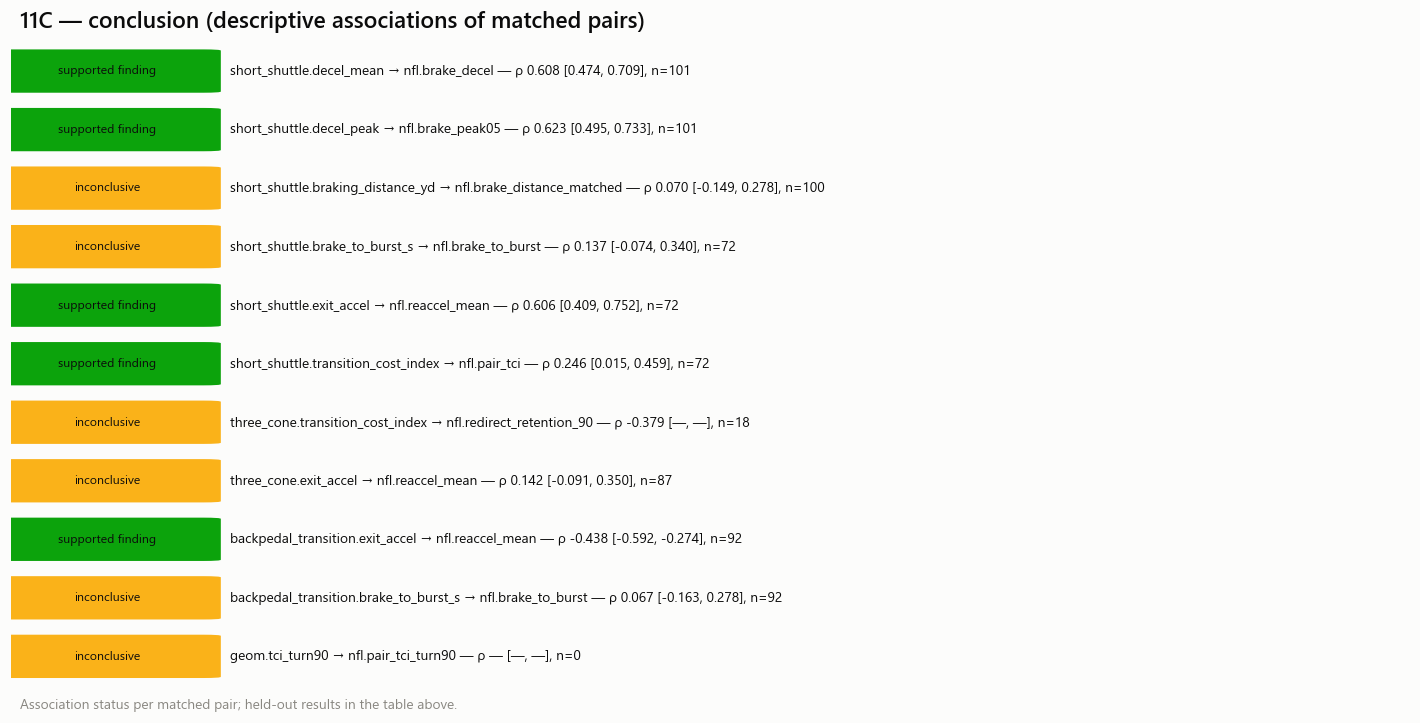

Send back: availability, segmenter summary, repeatability, variance decomposition, geometry cells, transfer and held-out tables, conclusion.
Next: 11a_drill_to_nfl_transfer_matrix.ipynb


In [9]:
icc = {r['feature']: r for r in rep.iter_rows(named=True)}
redm = {r['metric']: r for r in red.iter_rows(named=True)} if red.height else {}
sign = {p.combine + '|' + p.nfl: (-1 if 'NEGATIVE' in p.note and 'expected' in p.note else 1) for p in tr.TRANSFER_PAIRS}
evid = []
for m in metrics:
    a_ = assoc.filter((pl.col('combine') == m) & (pl.col('kind') == 'matched') & (pl.col('status') == 'computed')) if 'status' in assoc.columns else assoc.clear()
    a_ = a_.row(0, named=True) if a_.height else {}
    h = held.filter((pl.col('combine') == m)) if held.height else held
    h = h.row(0, named=True) if h.height else {}
    beats = None
    if control and m == feat and h:
        beats = bool(h.get('delta_rmse') is not None and h['delta_rmse'] > control['null_q95'])
    evid.append(tn.evidence_row(m, '11C', n_athletes=int(athf.filter(pl.col('feature') == m)['nfl_id'].n_unique()), icc=(icc.get(m) or {}).get('icc'), icc_lo=(icc.get(m) or {}).get('icc_lo'),
                                stopwatch_r2=(redm.get(m) or {}).get('r2_official'), nfl_comparison=a_.get('nfl'), cross_domain_rho=a_.get('spearman'), cross_domain_lo=a_.get('spearman_lo'),
                                cross_domain_hi=a_.get('spearman_hi'), expected_sign=sign.get(f"{m}|{a_.get('nfl')}", 1), delta_rmse=h.get('delta_rmse'), delta_lo=h.get('delta_lo'),
                                delta_hi=h.get('delta_hi'), beats_controls=beats, execution_mode=controls.run_mode, config_hash=C.hash()))
if asy.height:
    evid.append(tn.evidence_row('geom.asymmetry_abs', '11C', n_athletes=int(asy['comparable'].sum()), execution_mode=controls.run_mode, config_hash=C.hash(), note='magnitude only'))
adapt = (trans.filter(pl.col('abs_turn_angle_deg').is_not_null() & pl.col('transition_cost_index').is_finite()).group_by('nfl_id')
         .agg(pl.len().alias('k'), pl.cov('abs_turn_angle_deg', 'transition_cost_index').alias('c'), pl.col('abs_turn_angle_deg').var().alias('v')).filter((pl.col('k') >= 3) & (pl.col('v') > 0))) if trans.height else pl.DataFrame()
evid.append(tn.evidence_row('geom.adaptability_slope', '11C', n_athletes=adapt.height, execution_mode=controls.run_mode, config_hash=C.hash(), note='slope of TCI on |angle| per athlete'))
E = tn.evidence_frame(evid)
W(E, 'm11_metric_evidence_11C')
good_rep = rep_t.filter(pl.col('icc_lo') >= 0.5)['feature'].to_list() if rep_t.height else []
matched = assoc.filter((pl.col('kind') == 'matched') & (pl.col('status') == 'computed')) if 'status' in assoc.columns else assoc.clear()
verd = [h_['verdict'] for h_ in (held.iter_rows(named=True) if held.height else []) if h_.get('kind') == 'matched']
status = rp.comparison_status(verd, computed=bool(matched.height))
facts = {'status': status, 'run_mode': controls.run_mode,
         'sample': f"{trans['nfl_id'].n_unique() if trans.height else 0} Combine athletes with transitions ({trans.height:,} transitions); {data.height} linked athletes with ≥ 1 supported NFL target.",
         'evidence': [f"repeatable (ICC lower bound ≥ 0.5): {', '.join(good_rep) or 'none'}"]
                     + [f"{r['combine']} → {r['nfl']}: ρ {rp.ci(r['spearman'], r['spearman_lo'], r['spearman_hi'])}, n={r['n_athletes']} — {r['reading']}" for r in matched.iter_rows(named=True)]
                     + [f"held-out {r['combine']} → {r['target']}: Δ RMSE {rp.ci(r['delta_rmse'], r['delta_lo'], r['delta_hi'], 4)} ({r['verdict']})" for r in (held.iter_rows(named=True) if held.height else [])][:8]
                     + ([f"segmenter agreement (median): {', '.join(f'{r[0]} cp {r[1]:.2f} / hmm {r[2]:.2f}' for r in segsum.select('family', 'median_agree_changepoint', 'median_agree_hmm').rows())}"] if segsum.height else []),
         'alternatives': ['Drill technique (footwork coaching, plant foot) changes transition metrics without a capacity difference.', 'NFL transitions follow routes and coverage; their geometry is chosen, not imposed.',
                          'Non-forty participation is selected (see 11G).'],
         'relevance': 'Braking and re-acceleration are what the forty cannot see; a repeatable, nonredundant transition metric adds a measurable dimension even if NFL transfer is unproven.',
         'limitations': ['10 Hz sampling coarsens braking onset and latency (± 0.1 s).', 'Combine reversals pass through a stop, NFL turns mostly do not: few shared geometry cells.', 'Burst thresholds differ by domain (declared).'],
         'next': ['Collect tracked deceleration and cutting tests with controlled entry speed (10C proposals).', 'Repeat the geometry-matched comparison when more NFL turns with valid headings are available.']}
md_ = rp.conclusion_markdown('11C', facts)
display(Markdown(md_))
rp.write_conclusion(store, '11C', md_)
rp.run_manifest(store, '11C', PROV, ['m11_transition_repeatability', 'm11_transition_transfer', 'm11_transition_heldout', 'm11_metric_evidence_11C'], status)
crow = pl.DataFrame([{'item': f"{r['combine']} → {r['nfl']}", 'evidence': f"ρ {rp.ci(r['spearman'], r['spearman_lo'], r['spearman_hi'])}, n={r['n_athletes']}",
                      'status': 'supported_finding' if r['reading'].startswith('association') else 'inconclusive'} for r in matched.iter_rows(named=True)])
store.show(fg.fig_conclusion(crow, '11C — conclusion (descriptive associations of matched pairs)', 'Association status per matched pair; held-out results in the table above.'),
           'AM11_C_09_conclusion', {}, publication=True, source='m11_transition_transfer')
print('Send back: availability, segmenter summary, repeatability, variance decomposition, geometry cells, transfer and held-out tables, conclusion.')
print('Next: 11a_drill_to_nfl_transfer_matrix.ipynb')